**[Course Home](../README.md) | [Conceptual Track](../conceptual/00_START_HERE.ipynb) | [Next: Ch 01: Quantifying Surprise](01_self_information_and_shannon_entropy.ipynb)**

*Part I: Foundations of Uncertainty & Optimal Description — Chapter 00 of 11*

---

# Chapter 0: The Big Picture — Python Laboratory
### *Simulating the 20 Questions Game, Empirical Entropy, and Verifying Environment Capabilities*

Welcome to the Python Laboratory for Chapter 0! In this introductory workbook, we will verify our local scientific Python environment and simulate the physical mental model behind Shannon Information Theory: **The Game of 20 Questions**.

---

### Table of Contents
1. **Part 1: Environment Verification & Scientific Dependencies**
2. **Part 2: The 20 Questions Simulation (Uniform vs. Skewed Distributions)**
3. **Part 3: The Empirical Additivity of Information**
4. **Part 4: Multi-Panel Visualization of Ignorance Profiles**
5. **Part 5: Hands-On 3-Tier Scaffolding Challenges**


## Part 1: Environment Verification & Scientific Dependencies

Before running our information-theoretic simulations, we verify the core Python computational stack:
- **`numpy`**: Fast vectorized operations for probability distributions, matrix projections, and logarithmic calculations.
- **`scipy.stats`**: Analytical probability density/mass functions, Dirichlet priors, and sampling routines.
- **`matplotlib.pyplot`**: Visualizing probability landscapes, surprisal curves, and code-space geometry.
- **`pandas`**: Tabulating codebooks, bit-allocations, and compression metrics.

Numerical safeguard: In computational information theory, evaluating $\log_2(p)$ as $p \to 0$ leads to numerical singularities ($\log_2(0) = -\infty$). Throughout these laboratories, we enforce the standard mathematical convention:
$$\lim_{p \to 0^+} p \log_2 p = 0$$
implemented either by adding a negligible numerical floor ($\epsilon = 10^{-15}$) or filtering strictly positive probabilities ($p > 0$).

In [1]:
import sys
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd

print(f"Python Version: {sys.version.split()[0]}")
print(f"NumPy Version:  {np.__version__}")
print(f"SciPy Version:  {stats.__file__}")
print("Dependencies verified successfully!")


Python Version: 3.12.10
NumPy Version:  2.5.2
SciPy Version:  C:\Users\tarob\.jupyter_env\Lib\site-packages\scipy\stats\__init__.py
Dependencies verified successfully!


## Part 2: The 20 Questions Simulation

### Core Concepts & Governing Equations
Claude Shannon modeled information not as semantic meaning, but as the **resolution of uncertainty**. Consider the game of *20 Questions*: you must identify an unknown object $x$ drawn from a discrete set $\mathcal{X} = \{x_1, \dots, x_n\}$ with prior probabilities $P = (p_1, \dots, p_n)$.

1. **Self-Information (Surprisal)**:
   The information yielded by observing an individual outcome $x_i$ is inversely proportional to its likelihood:
   $$I(x_i) = -\log_2 p_i = \log_2 \left(\frac{1}{p_i}\right) \quad [\text{bits}]$$
   An event with $p_i = 1/2$ conveys exactly $1\text{ bit}$ of surprise (one binary choice). An outcome with $p_i = 1/8$ conveys $-\log_2(1/8) = 3\text{ bits}$ of surprise.

2. **Shannon Entropy as Expected Question Cost**:
   Each optimal binary question ("Is the item in subset $S$?") can eliminate at most half the remaining probability mass, providing at most $1\text{ bit}$ of information. Therefore, the average number of yes/no questions needed to identify $x$ is lower-bounded by the **Shannon Entropy** $H(X)$:
   $$H(X) = \mathbb{E}_{X \sim P}[I(X)] = -\sum_{i=1}^n p_i \log_2 p_i \quad [\text{bits}]$$

3. **Comparison of Scenarios Tested Below**:
   - **Uniform World** ($n=8$, $p_i = 1/8 = 0.125$):
     $$H_{\text{uniform}} = -\sum_{i=1}^8 \frac{1}{8} \log_2\left(\frac{1}{8}\right) = \log_2(8) = 3.0\text{ bits}$$
     Every state is equally surprising ($3\text{ bits}$), and binary search requires exactly 3 questions every single trial.
   - **Skewed World** ($p_0 = 0.80$, while $p_1, \dots, p_7$ share the remaining $0.20$):
     The frequent outcome state $0$ requires almost zero inquiry ($-\log_2(0.80) \approx 0.32\text{ bits}$), while rare states cost over $5\text{ bits}$. Weighted across all states:
     $$H_{\text{skewed}} = -\left(0.80 \log_2(0.80) + \sum_{i=1}^7 p_i \log_2 p_i\right) \approx 1.25\text{ bits}$$
     On average, you need fewer than half as many questions in the skewed world!

In [2]:
def simulate_20_questions(probs, n_trials=10000, seed=42):
    np.random.seed(seed)
    probs = np.asarray(probs, dtype=float)
    probs /= np.sum(probs)
    
    # Theoretical Shannon Entropy: H(X) = - sum(p * log2(p))
    theoretical_entropy = -np.sum(probs * np.log2(probs + 1e-15))
    
    # Draw actual random outcomes
    samples = np.random.choice(len(probs), size=n_trials, p=probs)
    
    # Optimal question cost is roughly -log2(p) (idealized binary prefix length)
    ideal_questions = -np.log2(probs[samples] + 1e-15)
    empirical_mean = np.mean(ideal_questions)
    empirical_std = np.std(ideal_questions)
    
    return theoretical_entropy, empirical_mean, empirical_std

# Define scenarios
p_uniform = np.ones(8) / 8.0
p_skewed = np.array([0.80, 0.05, 0.03, 0.03, 0.03, 0.02, 0.02, 0.02])

h_uni, emp_uni, std_uni = simulate_20_questions(p_uniform)
h_skew, emp_skew, std_skew = simulate_20_questions(p_skewed)

print("="*60)
print(f"UNIFORM WORLD:  Theoretical H = {h_uni:.4f} bits | Empirical Questions = {emp_uni:.4f} ± {std_uni:.4f}")
print(f"SKEWED WORLD:   Theoretical H = {h_skew:.4f} bits | Empirical Questions = {emp_skew:.4f} ± {std_skew:.4f}")
print("="*60)


UNIFORM WORLD:  Theoretical H = 3.0000 bits | Empirical Questions = 3.0000 ± 0.0000
SKEWED WORLD:   Theoretical H = 1.2676 bits | Empirical Questions = 1.2479 ± 1.8870


## Part 3: The Additivity Property of Information

### Fundamental Principle: Independence Implies Additivity
A foundational axiom of information theory is that learning about two statistically independent events must yield the sum of their individual surprises.

Let $X \in \mathcal{X}$ and $Y \in \mathcal{Y}$ be independent discrete random variables with marginal distributions $p_X(x)$ and $p_Y(y)$. By statistical independence:
$$p_{X, Y}(x, y) = p_X(x) \cdot p_Y(y)$$

Taking the logarithmic surprisal of the joint event:
$$I(x, y) = -\log_2 p_{X,Y}(x, y) = -\log_2(p_X(x) p_Y(y)) = -\log_2 p_X(x) - \log_2 p_Y(y) = I(x) + I(y)$$

Taking the expectation across all joint outcomes $(x, y) \in \mathcal{X} \times \mathcal{Y}$:
$$H(X, Y) = -\sum_{x \in \mathcal{X}} \sum_{y \in \mathcal{Y}} p(x, y) \log_2 p(x, y) = H(X) + H(Y)$$

In the numerical demonstration below:
- Fair Coin $X \in \{H, T\}$ ($p = 0.5$): $H(X) = \log_2(2) = 1.0\text{ bit}$.
- Fair 4-Sided Die $Y \in \{1, 2, 3, 4\}$ ($p = 0.25$): $H(Y) = \log_2(4) = 2.0\text{ bits}$.
- Joint State $(X, Y) \in \{H, T\} \times \{1, 2, 3, 4\}$: Exactly $H(X, Y) = 1.0 + 2.0 = 3.0\text{ bits}$.

In [3]:
# Coin Toss (p_heads = 0.5) and 4-sided Die (uniform 0.25)
px = np.array([0.5, 0.5])
py = np.array([0.25, 0.25, 0.25, 0.25])

hx = -np.sum(px * np.log2(px))
hy = -np.sum(py * np.log2(py))

# Joint Distribution P(X, Y) = P(X) * P(Y)
pxy = np.outer(px, py)
h_joint = -np.sum(pxy * np.log2(pxy))

print(f"H(Coin)       = {hx:.3f} bits")
print(f"H(4-Die)      = {hy:.3f} bits")
print(f"H(Coin + Die) = {h_joint:.3f} bits")
print(f"Additivity Check: H(X) + H(Y) = {hx + hy:.3f} == H(X,Y) = {h_joint:.3f} -> {np.isclose(hx + hy, h_joint)}")


H(Coin)       = 1.000 bits
H(4-Die)      = 2.000 bits
H(Coin + Die) = 3.000 bits
Additivity Check: H(X) + H(Y) = 3.000 == H(X,Y) = 3.000 -> True


## Part 4: Multi-Panel Visualization of Ignorance Profiles

### Structural Comparison: Flat vs. Peaked Uncertainty
To build physical intuition for entropy, we contrast the probability mass function $P(x_i)$ with the point surprise curve $I(x_i) = -\log_2 p(x_i)$ and decompose the entropy into state-wise contributions:
- **Uniform Profile**: Probabilities are completely flat ($p_i = 1/8$), which produces a completely flat surprise curve ($I(x_i) = 3.0\text{ bits}$). The variance of surprise is zero: every trial is equally informative.
- **Skewed Profile**: Probability mass concentrates on state $0$ ($p_0 = 0.80$), driving its surprise down to $I(x_0) \approx 0.32\text{ bits}$. Rare states ($p_i = 0.02$) carry high surprise ($I(x_i) \approx 5.64\text{ bits}$), but occur rarely.
- **Entropy as Expected Surprise ($H(X) = \mathbb{E}[I(X)]$):** Marked as horizontal dashed benchmark lines on the surprise panel. Notice how for the skewed distribution, despite 7 out of 8 states having $I(x_i) > 4.3\text{ bits}$, the overall entropy $H(X)$ is pulled down to $1.25\text{ bits}$ because the dominant state $0$ carries an 80% probability weighting.
- **Entropy Decomposition ($p(x_i) \cdot I(x_i)$):** In the third panel, each bar reflects the exact contribution of state $i$ to the total entropy. The heights sum directly to $H(X)$:
  $$H(X) = \sum_{i} p(x_i) I(x_i)$$

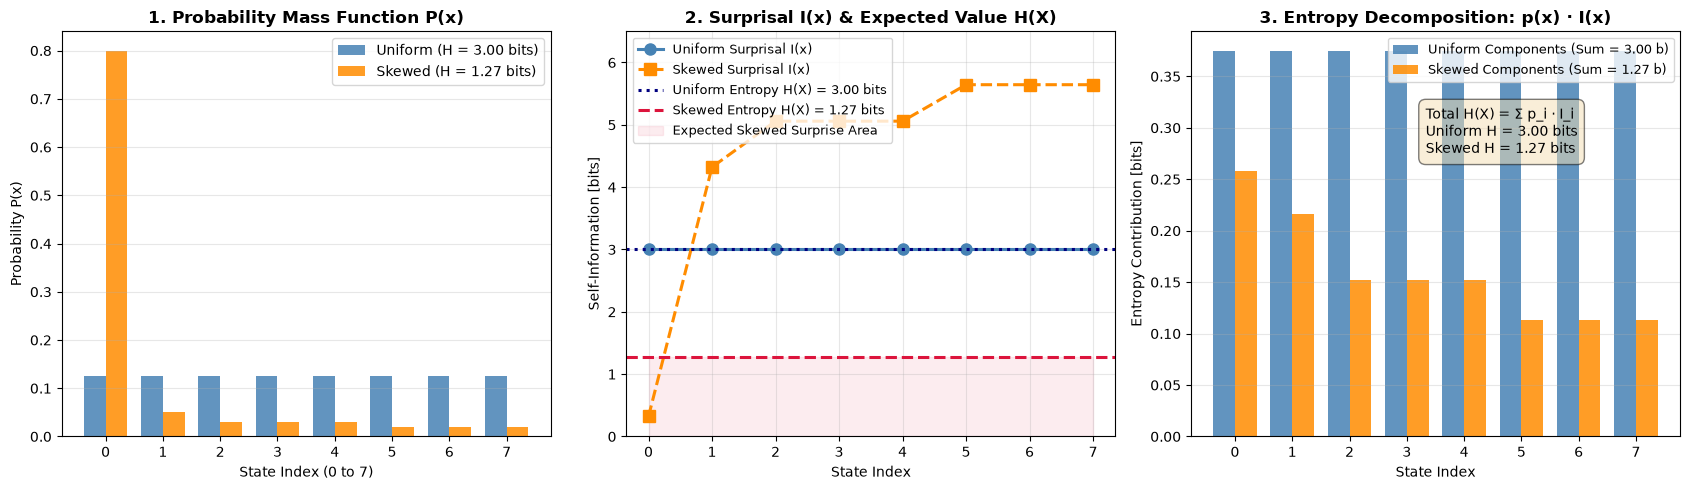

In [4]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 5))

indices = np.arange(8)
width = 0.38

# 1. Bar charts of probabilities
ax1.bar(indices - width/2, p_uniform, width=width, label=f"Uniform (H = {h_uni:.2f} bits)", color="steelblue", alpha=0.85)
ax1.bar(indices + width/2, p_skewed, width=width, label=f"Skewed (H = {h_skew:.2f} bits)", color="darkorange", alpha=0.85)
ax1.set_title("1. Probability Mass Function P(x)", fontsize=12, fontweight="bold")
ax1.set_xlabel("State Index (0 to 7)")
ax1.set_ylabel("Probability P(x)")
ax1.set_xticks(indices)
ax1.grid(True, alpha=0.3, axis="y")
ax1.legend(loc="upper right")

# 2. Point Surprise Curves: -log2(p) and Expected Value (Entropy H)
surprise_uni = -np.log2(p_uniform)
surprise_skew = -np.log2(p_skewed)
ax2.plot(indices, surprise_uni, 'o-', color="steelblue", lw=2.2, markersize=8, label="Uniform Surprisal I(x)")
ax2.plot(indices, surprise_skew, 's--', color="darkorange", lw=2.2, markersize=8, label="Skewed Surprisal I(x)")

# Visualizing Entropy: Horizontal Expected Value Lines
ax2.axhline(h_uni, color="navy", linestyle=":", lw=2.2, label=f"Uniform Entropy H(X) = {h_uni:.2f} bits")
ax2.axhline(h_skew, color="crimson", linestyle="--", lw=2.2, label=f"Skewed Entropy H(X) = {h_skew:.2f} bits")
ax2.fill_between(indices, 0, h_skew, color="crimson", alpha=0.08, label="Expected Skewed Surprise Area")

ax2.set_title("2. Surprisal I(x) & Expected Value H(X)", fontsize=12, fontweight="bold")
ax2.set_xlabel("State Index")
ax2.set_ylabel("Self-Information [bits]")
ax2.set_xticks(indices)
ax2.set_ylim(0, 6.5)
ax2.grid(True, alpha=0.3)
ax2.legend(loc="upper left", fontsize=9)

# 3. Weighted Contribution to Entropy: p(x) * I(x)
contrib_uni = p_uniform * surprise_uni
contrib_skew = p_skewed * surprise_skew

ax3.bar(indices - width/2, contrib_uni, width=width, label=f"Uniform Components (Sum = {h_uni:.2f} b)", color="steelblue", alpha=0.85)
ax3.bar(indices + width/2, contrib_skew, width=width, label=f"Skewed Components (Sum = {h_skew:.2f} b)", color="darkorange", alpha=0.85)
ax3.set_title("3. Entropy Decomposition: p(x) · I(x)", fontsize=12, fontweight="bold")
ax3.set_xlabel("State Index")
ax3.set_ylabel("Entropy Contribution [bits]")
ax3.set_xticks(indices)
ax3.grid(True, alpha=0.3, axis="y")
ax3.legend(loc="upper right", fontsize=9)

# Annotation summary card
ax3.text(0.48, 0.70, f"Total H(X) = Σ p_i · I_i\nUniform H = {h_uni:.2f} bits\nSkewed H = {h_skew:.2f} bits",
         transform=ax3.transAxes, fontsize=10,
         bbox=dict(boxstyle="round,pad=0.5", facecolor="wheat", alpha=0.5))

plt.tight_layout()
plt.show()

## Part 5: Hands-On 3-Tier Scaffolding Challenges

### 🟢 Warmup (Tier 1): The Fair 16-Sided Die
**Theoretical Context**:
For any discrete random variable with alphabet size $|\mathcal{X}| = K$, the entropy is maximized when all outcomes are equiprobable ($p_i = 1/K$):
$$H_{\max} = -\sum_{i=1}^K \frac{1}{K} \log_2\left(\frac{1}{K}\right) = \log_2(K) \quad [\text{bits}]$$
For a fair 16-sided die ($K = 16$, $p_i = 1/16$):
$$H(X) = \log_2(16) = 4.0 \quad [\text{bits}]$$
**Question-Game Intuition**:
Each optimal binary question bisects the remaining candidate outcomes:
$$16 \xrightarrow{Q_1} 8 \xrightarrow{Q_2} 4 \xrightarrow{Q_3} 2 \xrightarrow{Q_4} 1$$
Hence, exactly 4 yes/no questions are required to pinpoint the result.

In [5]:
# Tier 1 Solution Space
p_16 = np.ones(16) / 16.0
# Your calculation here:
h_16 = -np.sum(p_16 * np.log2(p_16))
print(f"Tier 1 Answer: H(16-sided die) = {h_16:.2f} bits.")


Tier 1 Answer: H(16-sided die) = 4.00 bits.


### 🟡 Diagnostic (Tier 2): Zipf's Law in Production
**Theoretical Context**:
In natural language, search query frequencies, and web traffic, items do not follow a uniform distribution; they follow **Zipf's Law**, where the probability of the $k$-th most frequent item is inversely proportional to its rank:
$$P(k) = \frac{k^{-s}}{\sum_{j=1}^N j^{-s}} = \frac{k^{-s}}{H_{N, s}}, \quad k \in \{1, 2, \dots, N\}$$
where $s \approx 1.0$ is the characteristic power-law exponent and $H_{N, s}$ is the generalized harmonic number.

**Perplexity as Effective Alphabet Size**:
**Perplexity** maps the entropy in bits back to an intuitive scale—the equivalent number of equally-likely outcomes needed to produce that same entropy:
$$\text{Perp}(X) = 2^{H(X)}$$
- A uniform distribution over $N=100$ items has $H = \log_2(100) \approx 6.64\text{ bits}$ and $\text{Perp} = 100$.
- A Zipfian distribution over $N=100$ items ($s=1.0$) concentrates probability mass in the top ranks ($p_1 \approx 19.3\%$, $p_2 \approx 9.6\%$), dramatically reducing uncertainty to $H \approx 4.37\text{ bits}$ and $\text{Perp} \approx 20.6$. It behaves like an effective fair 21-sided die!

In [6]:
# Tier 2 Solution Space
ranks = np.arange(1, 101)
zipf_probs = 1.0 / ranks
zipf_probs /= np.sum(zipf_probs)

h_zipf = -np.sum(zipf_probs * np.log2(zipf_probs))
perp_zipf = 2.0 ** h_zipf

h_uni100 = np.log2(100)
perp_uni100 = 100.0

print(f"Zipf(100):    H = {h_zipf:.2f} bits | Perplexity = {perp_zipf:.2f} (behaves like an ~{int(perp_zipf)}-sided die)")
print(f"Uniform(100): H = {h_uni100:.2f} bits | Perplexity = {perp_uni100:.2f} (behaves like a 100-sided die)")


Zipf(100):    H = 5.31 bits | Perplexity = 39.68 (behaves like an ~39-sided die)
Uniform(100): H = 6.64 bits | Perplexity = 100.00 (behaves like a 100-sided die)


### 🔴 Capstone Challenge (Tier 3): The Optimal First Question
**Theoretical Context**:
Given a 4-state system with prior distribution $P = [0.45, 0.35, 0.15, 0.05]$ and prior entropy $H(X) = -\sum_i p_i \log_2 p_i$, consider asking a binary question $Q \in \{\text{Yes}, \text{No}\}$ defined by a subset $S \subset \mathcal{X}$: "Is $X \in S$?"

1. **Marginal Probability of the Answer**:
   $$P(Q = \text{Yes}) = p_Y = \sum_{x \in S} p(x), \quad P(Q = \text{No}) = 1 - p_Y$$

2. **Posterior / Conditional Entropy**:
   If the answer is Yes, the updated distribution on $S$ is $p(x \mid \text{Yes}) = p(x)/p_Y$. The remaining uncertainty is:
   $$H(X \mid Q) = P(\text{Yes}) H(X \mid \text{Yes}) + P(\text{No}) H(X \mid \text{No})$$

3. **Information Gain (Mutual Information $I(X; Q)$)**:
   $$IG(Q) = H(X) - H(X \mid Q)$$
   Since the state $X$ deterministically dictates the answer to the question ($H(Q \mid X) = 0$), Information Gain is mathematically identical to the entropy of the question itself:
   $$IG(Q) = H(Q) = -p_Y \log_2 p_Y - (1 - p_Y) \log_2 (1 - p_Y)$$
   **Core Rule**: The optimal question is the one whose total probability $p_Y = P(S)$ is closest to $0.5$, which maximizes $H(Q) \le 1.0\text{ bit}$.

In [7]:
# Tier 3 Solution Space
p = np.array([0.45, 0.35, 0.15, 0.05])
h_prior = -np.sum(p * np.log2(p))

# Candidate Split: Is it in {0}? (prob = 0.45)
# Candidate Split: Is it in {0, 1}? (prob = 0.45 + 0.35 = 0.80)
# Candidate Split: Is it in {0, 2}? (prob = 0.45 + 0.15 = 0.60)
candidates = [
    ([0], [1, 2, 3]),
    ([0, 1], [2, 3]),
    ([0, 2], [1, 3]),
    ([0, 3], [1, 2])
]

print(f"Prior Entropy H(X): {h_prior:.3f} bits\n")
for group_yes, group_no in candidates:
    p_yes = np.sum(p[group_yes])
    p_no = 1.0 - p_yes
    
    # Conditional entropy H(X | Question)
    p_cond_yes = p[group_yes] / p_yes
    p_cond_no = p[group_no] / p_no
    
    h_yes = -np.sum(p_cond_yes * np.log2(p_cond_yes + 1e-15))
    h_no = -np.sum(p_cond_no * np.log2(p_cond_no + 1e-15))
    
    h_cond = p_yes * h_yes + p_no * h_no
    info_gain = h_prior - h_cond
    print(f"Split {group_yes} vs {group_no}: P(Yes)={p_yes:.2f} | Remaining H={h_cond:.3f} | Info Gain={info_gain:.3f} bits")


Prior Entropy H(X): 1.675 bits

Split [0] vs [1, 2, 3]: P(Yes)=0.45 | Remaining H=0.682 | Info Gain=0.993 bits
Split [0, 1] vs [2, 3]: P(Yes)=0.80 | Remaining H=0.953 | Info Gain=0.722 bits
Split [0, 2] vs [1, 3]: P(Yes)=0.60 | Remaining H=0.704 | Info Gain=0.971 bits
Split [0, 3] vs [1, 2]: P(Yes)=0.50 | Remaining H=0.675 | Info Gain=1.000 bits


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/00_START_HERE.ipynb) | [Next: Ch 01: Quantifying Surprise](01_self_information_and_shannon_entropy.ipynb)**
